In [1]:
!pip install torchxrayvision --no-deps -q
!pip install scikit-image rouge-score nltk seaborn -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 53.5 MB/s eta 0:00:00:00:0100:01


In [2]:
import os, json, torch, torch.nn as nn, pandas as pd, numpy as np, nltk
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
from tqdm import tqdm
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from rouge_score import rouge_scorer
from sklearn.metrics import f1_score, precision_score, recall_score, multilabel_confusion_matrix
import torchxrayvision as xrv

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
tokenizer.add_special_tokens({"bos_token": "<bos>", "eos_token": "<eos>", "pad_token": "<pad>"})
vocab_size = len(tokenizer)
pad_id = tokenizer.pad_token_id
bos_id = tokenizer.bos_token_id
eos_id = tokenizer.eos_token_id

Device: cpu


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [3]:
# Auto-detect manifest from working or input
manifest_candidates = [
    "/kaggle/working/mimic_master_split.csv",
]
# Search in all attached inputs
import subprocess
result = subprocess.run(
    "find /kaggle/input -name 'mimic_master_split.csv' 2>/dev/null",
    shell=True, capture_output=True, text=True
)
for path in result.stdout.strip().split("\n"):
    if path:
        manifest_candidates.append(path)

manifest_path = None
for p in manifest_candidates:
    if os.path.exists(p):
        manifest_path = p
        break

if manifest_path is None:
    # Regenerate from scratch using attached inputs
    raise FileNotFoundError("mimic_master_split.csv not found. Run the data preparation cell below.")

print(f"Manifest loaded from: {manifest_path}")
master_df = pd.read_csv(manifest_path)

train_df = master_df[master_df['split'] == 'train']
val_df   = master_df[master_df['split'] == 'val']
test_df  = master_df[master_df['split'] == 'test']
print(f"Test set: {len(test_df):,} samples")

Manifest loaded from: /kaggle/input/models/alinikoukar/mimic-cxr-report-gen-main/pytorch/default/1/mimic_master_split.csv
Test set: 5,731 samples


In [4]:
class BaselineDataset(Dataset):
    def __init__(self, df, tokenizer, max_seq_len=100):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_seq_len = max_seq_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            img = Image.open(row['image_path']).convert('L').resize((224, 224))
            img_np = np.array(img, dtype=np.float32)
            img_normalized = xrv.datasets.normalize(img_np, maxval=255)
            image_tensor = torch.tensor(img_normalized, dtype=torch.float32).unsqueeze(0)
        except Exception:
            image_tensor = torch.zeros((1, 224, 224), dtype=torch.float32)

        report_text = str(row['report']) if pd.notna(row['report']) else ""
        tokenized = self.tokenizer(
            f"<bos> {report_text} <eos>",
            max_length=self.max_seq_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        return {
            "image": image_tensor,
            "input_ids": tokenized["input_ids"].squeeze(0)
        }

test_dataset = BaselineDataset(test_df, tokenizer, max_seq_len=100)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
print(f"Test DataLoader: {len(test_loader):,} batches ({len(test_dataset):,} samples)")

Test DataLoader: 180 batches (5,731 samples)


In [5]:
class BaselineDenseNetLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=256, hidden_dim=512, pad_token_id=0):
        super().__init__()
        self.vocab_size = vocab_size
        self.pad_token_id = pad_token_id
        self.hidden_dim = hidden_dim
        densenet = xrv.models.DenseNet(weights="densenet121-res224-mimic_ch")
        self.encoder = densenet.features
        for param in self.encoder.parameters():
            param.requires_grad = False
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.init_h = nn.Linear(1024, hidden_dim)
        self.init_c = nn.Linear(1024, hidden_dim)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_token_id)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc_out = nn.Linear(hidden_dim, vocab_size)

    def extract_visual_features(self, images):
        with torch.no_grad():
            features = self.encoder(images)
        return self.global_pool(features).flatten(1)

    def forward(self, images, input_ids):
        features = self.extract_visual_features(images)
        h_0 = torch.tanh(self.init_h(features)).unsqueeze(0)
        c_0 = torch.tanh(self.init_c(features)).unsqueeze(0)
        embeddings = self.embedding(input_ids[:, :-1])
        lstm_out, _ = self.lstm(embeddings, (h_0, c_0))
        return self.fc_out(lstm_out)

    @torch.no_grad()
    def greedy_generate(self, image, max_len=60):
        self.eval()
        if image.dim() == 3:
            image = image.unsqueeze(0)
        features = self.extract_visual_features(image)
        h = torch.tanh(self.init_h(features)).unsqueeze(0)
        c = torch.tanh(self.init_c(features)).unsqueeze(0)
        current_token = torch.tensor([[bos_id]], device=image.device)
        generated = []
        for _ in range(max_len):
            emb = self.embedding(current_token)
            out, (h, c) = self.lstm(emb, (h, c))
            next_id = self.fc_out(out.squeeze(1)).argmax(-1).item()
            if next_id == eos_id:
                break
            generated.append(next_id)
            current_token = torch.tensor([[next_id]], device=image.device)
        return generated

# Auto-detect checkpoint
result = subprocess.run(
    "find /kaggle/input -name 'baseline_a_best.pt' 2>/dev/null",
    shell=True, capture_output=True, text=True
)
checkpoint_path = result.stdout.strip().split("\n")[0]
print(f"Checkpoint found at: {checkpoint_path}")

model = BaselineDenseNetLSTM(vocab_size=vocab_size, pad_token_id=pad_id).to(device)
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()
print("Model loaded successfully.")

Checkpoint found at: /kaggle/input/models/alinikoukar/mimic-cxr-report-gen-main/pytorch/default/1/baseline_a_best.pt
If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/mimic_ch-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /root/.torchxrayvision/models_data/mimic_ch-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]
Model loaded successfully.


[Evaluation] Running on 5,731 test cases...


Test Set: 100%|██████████| 5731/5731 [32:00<00:00,  2.98it/s]



BENCHMARK RESULTS: Baseline A
  BLEU-1                        : 0.2885
  BLEU-2                        : 0.2305
  BLEU-3                        : 0.1959
  BLEU-4                        : 0.1756
  ROUGE-1                       : 0.307
  ROUGE-2                       : 0.219
  ROUGE-L                       : 0.3024
  Clinical_Macro_F1             : 0.1043
  Clinical_Micro_F1             : 0.3328
  Clinical_Micro_Precision      : 0.4606
  Clinical_Micro_Recall         : 0.2605

PER-PATHOLOGY BREAKDOWN
Pathology                  | TP    | FP    | FN    | TN    | Prec    | Recall  | F1     
-----------------------------------------------------------------------------------------------
Atelectasis                | 71    | 114   | 1046  | 4500  | 0.3838  | 0.0636  | 0.1091 
Cardiomegaly               | 19    | 62    | 540   | 5110  | 0.2346  | 0.0340  | 0.0594 
Consolidation              | 1     | 16    | 519   | 5195  | 0.0588  | 0.0019  | 0.0037 
Edema                      | 150   | 180   

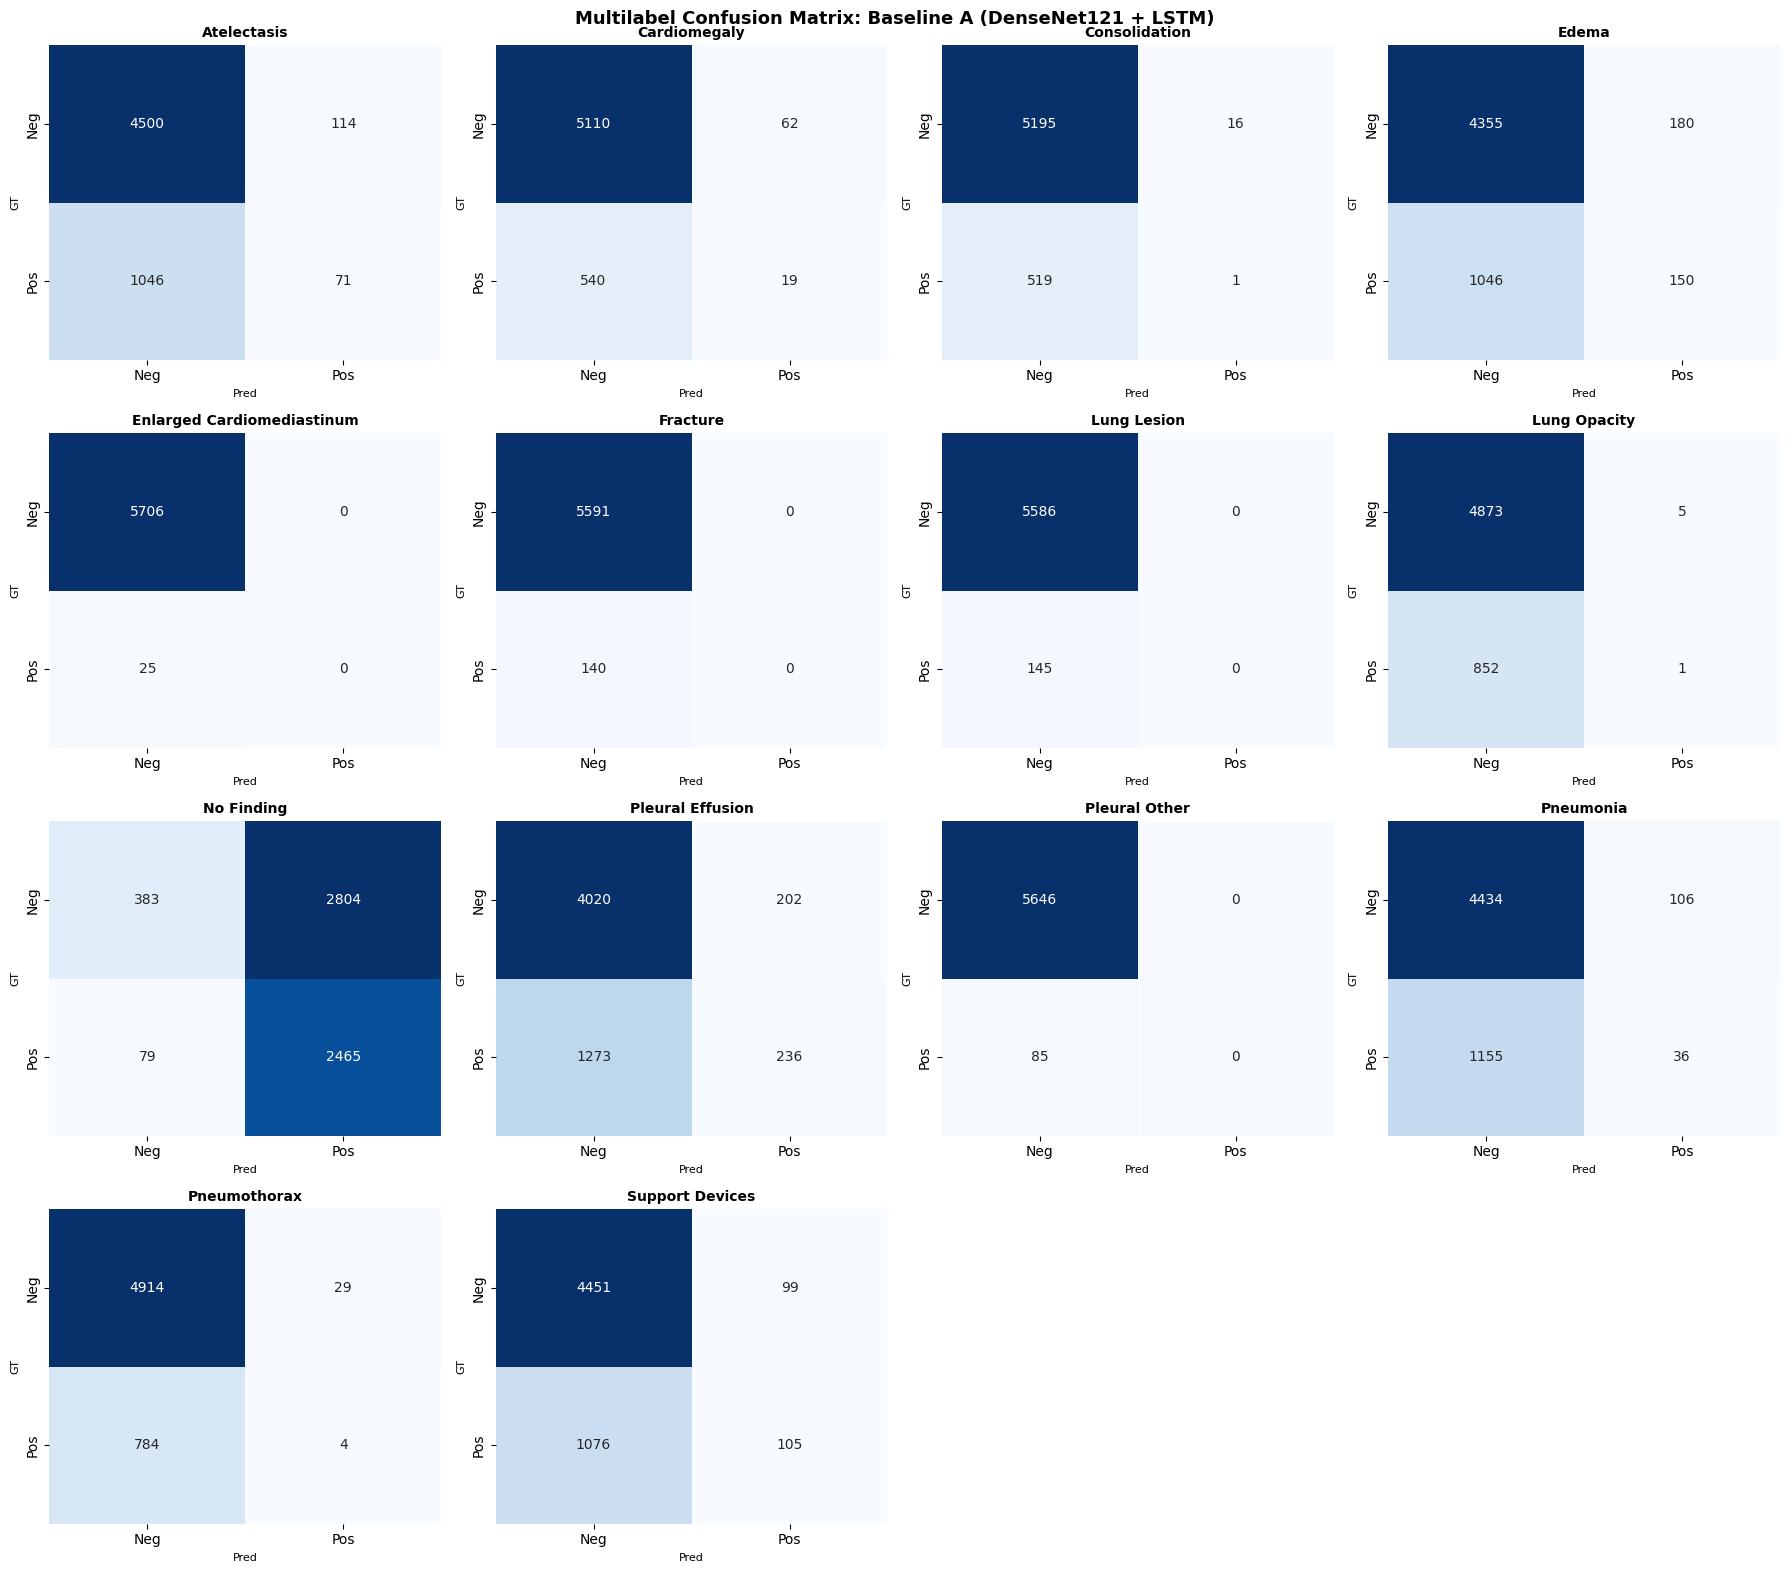


QUALITATIVE CASE STUDIES

[Case #1] Study: 52067803
  GT  : Mild left base atelectasis. Otherwise, no acute cardiopulmonary process.
  Pred: No acute cardiopulmonary process.
  BLEU-4=0.2466 | ROUGE-L=0.6154
---------------------------------------------------------------------------

[Case #2] Study: 52067803
  GT  : Mild left base atelectasis. Otherwise, no acute cardiopulmonary process.
  Pred: No acute cardiopulmonary process.
  BLEU-4=0.2466 | ROUGE-L=0.6154
---------------------------------------------------------------------------

[Case #3] Study: 50084553
  GT  : , most _ _ _. Large right moderate left pleural effusions and severe bibasilar atelectasis unchanged. Cardiac silhouette is obscured. No pneumothorax. Pulmonary edema is mild, obscured radiographically by overlying abnormalities.
  Pred: The right pleural effusion. The left pleural effusion decreased. The right lung is clear.
  BLEU-4=0.0109 | ROUGE-L=0.2439
------------------------------------------------------------

In [6]:
clinical_keywords = {
    'Atelectasis': ['atelectasis', 'atelectatic', 'collapse', 'volume loss'],
    'Cardiomegaly': ['cardiomegaly', 'enlarged heart', 'enlarged cardiac', 'cardiac enlargement'],
    'Consolidation': ['consolidation', 'airspace disease', 'airspace opacity'],
    'Edema': ['edema', 'vascular congestion', 'fluid overload', 'interstitial edema'],
    'Enlarged Cardiomediastinum': ['widened mediastinum', 'mediastinal widening', 'cardiomediastinum'],
    'Fracture': ['fracture', 'fractured', 'broken rib', 'healing fracture'],
    'Lung Lesion': ['lung lesion', 'nodule', 'mass', 'nodular opacity'],
    'Lung Opacity': ['opacity', 'opacities', 'infiltrate', 'clouding'],
    'No Finding': ['normal', 'clear', 'unremarkable', 'no acute', 'negative'],
    'Pleural Effusion': ['pleural effusion', 'effusion', 'blunting', 'fluid in pleural'],
    'Pleural Other': ['pleural thickening', 'fibrosis', 'calcification'],
    'Pneumonia': ['pneumonia', 'infectious process', 'bronchopneumonia'],
    'Pneumothorax': ['pneumothorax', 'air in pleural', 'apical pneumothorax'],
    'Support Devices': ['tube', 'catheter', 'pacemaker', 'pacer', 'line', 'picc', 'stent']
}

smooth = SmoothingFunction().method1
rouge_evaluator = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

results = []
bleu1_scores, bleu2_scores, bleu3_scores, bleu4_scores = [], [], [], []
rouge1_scores, rouge2_scores, rougeL_scores = [], [], []
gt_pathology_matrix, pred_pathology_matrix = [], []

print(f"[Evaluation] Running on {len(test_dataset):,} test cases...")
with torch.no_grad():
    for idx in tqdm(range(len(test_dataset)), desc="Test Set"):
        row = test_df.iloc[idx]
        image_tensor = test_dataset[idx]["image"].to(device)

        gen_tokens = model.greedy_generate(image_tensor, max_len=60)
        pred_text = tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()
        gt_text = str(row['report']).strip()

        ref_tokens = [nltk.word_tokenize(gt_text.lower())] if gt_text else [[""]]
        hyp_tokens = nltk.word_tokenize(pred_text.lower()) if pred_text else [""]

        b1 = sentence_bleu(ref_tokens, hyp_tokens, weights=(1,0,0,0), smoothing_function=smooth)
        b2 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.5,0.5,0,0), smoothing_function=smooth)
        b3 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.33,0.33,0.33,0), smoothing_function=smooth)
        b4 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.25,0.25,0.25,0.25), smoothing_function=smooth)
        rouge_res = rouge_evaluator.score(gt_text, pred_text)

        bleu1_scores.append(b1); bleu2_scores.append(b2)
        bleu3_scores.append(b3); bleu4_scores.append(b4)
        rouge1_scores.append(rouge_res['rouge1'].fmeasure)
        rouge2_scores.append(rouge_res['rouge2'].fmeasure)
        rougeL_scores.append(rouge_res['rougeL'].fmeasure)

        gt_row  = [int(any(kw in gt_text.lower()   for kw in kws)) for kws in clinical_keywords.values()]
        pred_row = [int(any(kw in pred_text.lower() for kw in kws)) for kws in clinical_keywords.values()]
        gt_pathology_matrix.append(gt_row)
        pred_pathology_matrix.append(pred_row)

        results.append({
            "dicom_id": row["dicom_id"], "study_id": row["study_id"],
            "ground_truth": gt_text, "prediction": pred_text,
            "bleu1": round(b1,4), "bleu4": round(b4,4),
            "rougeL": round(rouge_res['rougeL'].fmeasure,4)
        })

gt_matrix   = np.array(gt_pathology_matrix)
pred_matrix = np.array(pred_pathology_matrix)

summary_metrics = {
    "Model": "Baseline A (DenseNet121 + Vanilla LSTM)",
    "Test_Samples": len(results),
    "BLEU-1":  round(float(np.mean(bleu1_scores)),  4),
    "BLEU-2":  round(float(np.mean(bleu2_scores)),  4),
    "BLEU-3":  round(float(np.mean(bleu3_scores)),  4),
    "BLEU-4":  round(float(np.mean(bleu4_scores)),  4),
    "ROUGE-1": round(float(np.mean(rouge1_scores)), 4),
    "ROUGE-2": round(float(np.mean(rouge2_scores)), 4),
    "ROUGE-L": round(float(np.mean(rougeL_scores)), 4),
    "Clinical_Macro_F1":        round(float(f1_score(gt_matrix, pred_matrix, average='macro',  zero_division=0)), 4),
    "Clinical_Micro_F1":        round(float(f1_score(gt_matrix, pred_matrix, average='micro',  zero_division=0)), 4),
    "Clinical_Micro_Precision": round(float(precision_score(gt_matrix, pred_matrix, average='micro', zero_division=0)), 4),
    "Clinical_Micro_Recall":    round(float(recall_score(gt_matrix, pred_matrix, average='micro',    zero_division=0)), 4),
}

print("\n" + "="*70)
print("BENCHMARK RESULTS: Baseline A")
print("="*70)
for k, v in summary_metrics.items():
    if k not in ["Model", "Test_Samples"]:
        print(f"  {k:<30}: {v}")

pathology_names = list(clinical_keywords.keys())
mcm = multilabel_confusion_matrix(gt_matrix, pred_matrix)
pathology_stats = []

print("\n" + "="*95)
print("PER-PATHOLOGY BREAKDOWN")
print("="*95)
print(f"{'Pathology':<26} | {'TP':<5} | {'FP':<5} | {'FN':<5} | {'TN':<5} | {'Prec':<7} | {'Recall':<7} | {'F1':<7}")
print("-"*95)
for i, name in enumerate(pathology_names):
    tn, fp, fn, tp = mcm[i].ravel()
    prec = tp/(tp+fp) if (tp+fp)>0 else 0.0
    rec  = tp/(tp+fn) if (tp+fn)>0 else 0.0
    f1   = 2*prec*rec/(prec+rec) if (prec+rec)>0 else 0.0
    pathology_stats.append({"Pathology":name,"TP":int(tp),"FP":int(fp),"FN":int(fn),"TN":int(tn),
                             "Precision":round(prec,4),"Recall":round(rec,4),"F1_Score":round(f1,4)})
    print(f"{name:<26} | {tp:<5} | {fp:<5} | {fn:<5} | {tn:<5} | {prec:<7.4f} | {rec:<7.4f} | {f1:<7.4f}")

# Confusion Matrix Plot
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()
for i, name in enumerate(pathology_names):
    sns.heatmap(mcm[i], annot=True, fmt="d", cmap="Blues", cbar=False,
                ax=axes[i], xticklabels=["Neg","Pos"], yticklabels=["Neg","Pos"])
    axes[i].set_title(name, fontsize=10, fontweight='bold')
    axes[i].set_ylabel("GT", fontsize=8)
    axes[i].set_xlabel("Pred", fontsize=8)
for j in range(len(pathology_names), len(axes)):
    fig.delaxes(axes[j])
plt.suptitle("Multilabel Confusion Matrix: Baseline A (DenseNet121 + LSTM)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("/kaggle/working/baseline_a_confusion_matrices.png", dpi=300, bbox_inches='tight')
plt.show()

# Case Studies
print("\n" + "="*75)
print("QUALITATIVE CASE STUDIES")
print("="*75)
for i in range(min(5, len(results))):
    print(f"\n[Case #{i+1}] Study: {results[i]['study_id']}")
    print(f"  GT  : {results[i]['ground_truth']}")
    print(f"  Pred: {results[i]['prediction']}")
    print(f"  BLEU-4={results[i]['bleu4']} | ROUGE-L={results[i]['rougeL']}")
    print("-"*75)

# Save artifacts
pd.DataFrame(results).to_csv("/kaggle/working/baseline_a_test_predictions.csv", index=False)
pd.DataFrame(pathology_stats).to_csv("/kaggle/working/baseline_a_pathology_breakdown.csv", index=False)
with open("/kaggle/working/baseline_a_test_metrics.json", "w") as f:
    json.dump(summary_metrics, f, indent=2)

print("\nAll artifacts saved to /kaggle/working/")